# 03 - Convolutional coding, puncturing and Viterbi decoding
**Objective.** Implement and verify the rate-1/2, K=7, generators (133, 171)$_8$ code, its punctured rates 2/3 and 3/4 and the soft-decision Viterbi decoder.

**Concept.** The encoder is a 6-bit shift register (64 states). Each input bit produces two coded bits
$c_A=\text{parity}(\text{reg}\,\&\,133_8)$, $c_B=\text{parity}(\text{reg}\,\&\,171_8)$. Six zero **tail bits** return the register to state 0 (termination), so $L$ information bits give $2(L+6)$ coded bits.

**Puncturing** deletes coded bits following a periodic mask, raising the rate: the 2/3 mask keeps 3 of every 4 coded bits ($\tfrac12\cdot\tfrac43=\tfrac23$), the 3/4 mask keeps 4 of every 6 ($\tfrac12\cdot\tfrac32=\tfrac34$). The decoder re-inserts **zero LLRs** (no information) at deleted positions ("depuncturing") and runs the *same* rate-1/2 trellis.

**LLR convention.** $\text{LLR}=\ln\frac{P(c=0)}{P(c=1)}$, positive means bit 0. Viterbi maximises $\sum \text{LLR}\cdot(1-2c)/2$.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))          # project root = import root
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIG, TAB = ROOT / "results/figures", ROOT / "results/tables"
print("project root:", ROOT)

project root: /home/amardeep/Downloads/Project_Checkpoint_06/Exercise1


In [2]:
from task1_conventional import convolutional as cv
from task1_conventional.viterbi import viterbi_single, viterbi_decode
rng = np.random.default_rng(0)

## 1. Encoder verification: impulse response = generator polynomials

In [3]:
out = cv.encode_mother([1]); A, B = out[0::2], out[1::2]
print("133 octal =", format(0o133, "07b"), "-> branch A response", "".join(map(str, A)))
print("171 octal =", format(0o171, "07b"), "-> branch B response", "".join(map(str, B)))
assert "".join(map(str, A)) == format(0o133, "07b") and "".join(map(str, B)) == format(0o171, "07b")
b = rng.integers(0, 2, 100)
assert np.array_equal(cv.encode_mother(b), cv.encode_reference(b)); print("fast encoder == shift-register reference encoder")
nxt, o = cv.trellis(); s = 0
for x in list(b) + [0]*6: s = nxt[s, x]
print("final state after termination:", s, "| coded length", len(cv.encode_mother(b)), "= 2*(100+6)")

133 octal = 1011011 -> branch A response 1011011
171 octal = 1111001 -> branch B response 1111001
fast encoder == shift-register reference encoder
final state after termination: 0 | coded length 212 = 2*(100+6)


## 2. Puncturing patterns and effective rate

In [4]:
rows = []
for r, m in cv.PUNCTURE_MASKS.items():
    rows.append(dict(rate=r, mask="".join(map(str, m.astype(int))), period_coded_bits=len(m), kept=int(m.sum()),
                     nominal_rate=str(cv.nominal_rate(r)),
                     eff_rate_L=" / ".join(f"{L}: {cv.effective_rate(L, r):.4f}" for L in (50, 350, 1000))))
display(pd.DataFrame(rows))

,rate,mask,period_coded_bits,kept,nominal_rate,eff_rate_L
0,1/2,11,2,2,1/2,50: 0.4464 / 350: 0.4916 / 1000: 0.4970
1,2/3,1110,4,3,2/3,50: 0.5952 / 350: 0.6554 / 1000: 0.6627
2,3/4,111001,6,4,3/4,50: 0.6667 / 350: 0.7368 / 1000: 0.7452


The **effective** rate of a finite frame is slightly below nominal because the 6 tail bits are also transmitted (and all coded bits of the tail are kept in the mother stream). For the sentence lengths used here (~330 info bits) this costs about 1.7 %. The AMC rule uses the *nominal* rate $m\cdot R$ for spectral efficiency; the effective rate is reported for completeness.

## 3. Noiseless recovery at all three rates

In [5]:
for rate in cv.PUNCTURE_MASKS:
    ok = True
    for n in (1, 6, 7, 50, 333):
        b = rng.integers(0, 2, n); m = cv.encode_mother(b)
        llr = cv.depuncture(8.0 * (1 - 2.0 * cv.puncture(m, rate)), rate, len(m))
        ok &= np.array_equal(viterbi_single(llr, n), b)
    print(f"rate {rate}: noiseless exact recovery for all tested lengths ->", ok)

rate 1/2: noiseless exact recovery for all tested lengths -> True
rate 2/3: noiseless exact recovery for all tested lengths -> True
rate 3/4: noiseless exact recovery for all tested lengths -> True


## 4. Is the Viterbi decoder really *maximum likelihood*?
For short frames we can brute-force **all** $2^k$ codewords and pick the best soft metric. Viterbi must achieve the same metric.

In [6]:
import itertools
k = 8; cws = {bits: cv.encode_mother(bits) for bits in itertools.product([0, 1], repeat=k)}
agree = 0; trials = 300
for _ in range(trials):
    u = rng.integers(0, 2, k); x = 1 - 2.0 * cv.encode_mother(u)
    llr = 2 * (x + rng.normal(0, 1.0, len(x)))
    d = tuple(viterbi_single(llr, k))
    best = max(cws, key=lambda c: np.sum(llr * (1 - 2.0 * cws[c])))
    agree += np.isclose(np.sum(llr*(1-2.0*cws[d])), np.sum(llr*(1-2.0*cws[best])))
print(f"Viterbi metric == brute-force ML metric in {agree}/{trials} noisy trials")

Viterbi metric == brute-force ML metric in 300/300 noisy trials


## 5. Coding gain: BPSK + soft Viterbi over AWGN
Quick Monte-Carlo (400 frames x 500 bits per point). Axis = $E_b/N_0$, where for rate $R$ BPSK: $E_s/N_0 = R\,E_b/N_0$ (a *coded* bit carries only $R$ information bits of energy).

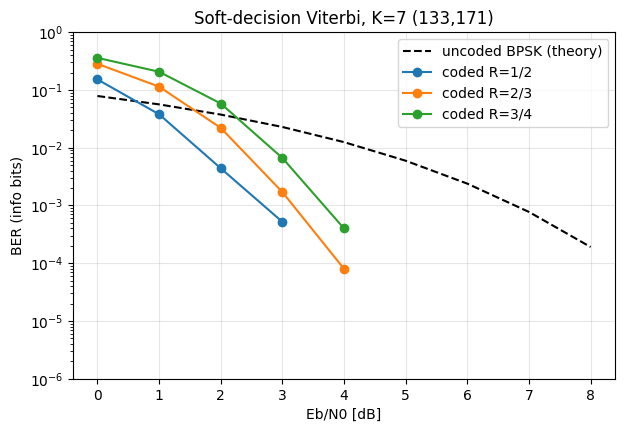

(points with zero errors are omitted; each point is based on 200000 bits - resolution ~ 5e-06 )


In [7]:
from task1_conventional.modulation import Modem
from task1_conventional.demapper import llr_maxlog
from task1_conventional import channel as ch
from scipy.special import erfc
bpsk = Modem("BPSK"); eb_grid = np.arange(0, 8.1, 1.0); nfr, L = 400, 500
res = {}
for rate in cv.PUNCTURE_MASKS:
    R = float(cv.nominal_rate(rate)); ber_l = []
    for eb in eb_grid:
        es = ch.ebn0_to_esn0_db(eb, 1, R); errs = 0
        tx = rng.integers(0, 2, (nfr, L)); T = L + 6
        llr = np.zeros((nfr, 2 * T), dtype=np.float32)
        for i in range(nfr):
            m = cv.encode_mother(tx[i]); p = cv.puncture(m, rate)
            y, n0 = ch.awgn(bpsk.modulate(p), es, rng)
            llr[i] = cv.depuncture(llr_maxlog(y, n0, bpsk), rate, len(m))
        dec = viterbi_decode(llr, np.full(nfr, L))[:, :L]
        ber_l.append(np.mean(dec != tx))
    res[rate] = ber_l
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogy(eb_grid, 0.5 * erfc(np.sqrt(10 ** (eb_grid / 10))), "k--", label="uncoded BPSK (theory)")
for rate, v in res.items(): ax.semilogy(eb_grid, np.where(np.array(v) > 0, v, np.nan), "o-", label=f"coded R={rate}")
ax.set_ylim(1e-6, 1); ax.set_xlabel("Eb/N0 [dB]"); ax.set_ylabel("BER (info bits)"); ax.legend(); ax.set_title("Soft-decision Viterbi, K=7 (133,171)")
fig.savefig(FIG / "conv_code_gain_bpsk.png", dpi=150); plt.show()
print("(points with zero errors are omitted; each point is based on", nfr * L, "bits - resolution ~", 1 / (nfr * L), ")")

Higher rates (more puncturing) lose coding gain and need larger $E_b/N_0$ for the same BER - the price of the higher spectral efficiency.